# fotoapp — notebook de pruebas (`fotoapp_testdev.ipynb`)

**Programación Python Avanzada — TUTP 2026 — Proyecto 2, primera parte**

Integrantes: Sofia Martin, Laura Sofía Pérez Llanqueleo

En este notebook probamos, una por una, las funciones del módulo `fotoapp.py`:

1. `redimensionar_para_red()`: lee la foto (archivo, Google Drive o URL) y la lleva al tamaño de cada red social sin deformarla.
2. `ecualizar_histograma()`: ajusta el contraste con el histograma (una foto oscura y otra con exceso de luz).
3. `aplicar_filtro()`: aplica los 9 filtros de Pillow.
4. `boceto()` / `comparar_bocetos()`: boceto de líneas con varias técnicas de detección de bordes.
5. `menu()`: menú de opciones que obliga a pasar primero por la función 1.

Como pide la consigna, usamos **una foto distinta para cada función**. Las imágenes originales están en `imagenes/originales/` y todo lo que se genera se guarda en `imagenes/generadas/`.

> El notebook funciona tanto en **Google Colab** como en **Jupyter** local.

## 0. Configuración Colab

In [1]:
import os
import subprocess
import sys

# Repositorio donde está subido el proyecto (cambiarlo si el repo tiene otro nombre)
REPO_URL = "https://github.com/SofiMartin/proyecto2-python-avanzado.git"
CARPETA_PARTE1 = "proyecto2-python-avanzado/parte1_fotoapp"

EN_COLAB = "google.colab" in sys.modules

if EN_COLAB and not os.path.exists("fotoapp.py"):
    # En Colab clonamos el repo para tener fotoapp.py y las imágenes de prueba
    nombre_repo = REPO_URL.rstrip("/").split("/")[-1].removesuffix(".git")
    if not os.path.exists(nombre_repo):
        subprocess.run(["git", "clone", "-q", REPO_URL], check=True)
    os.chdir(os.path.join(nombre_repo, CARPETA_PARTE1))

print("¿Estamos en Colab?:", EN_COLAB)
print("Directorio de trabajo:", os.getcwd())

¿Estamos en Colab?: False
Directorio de trabajo: C:\Users\Maria\Downloads\proyecto2-python-avanzado 2\proyecto2-python-avanzado\parte1_fotoapp


**Opcional (solo Colab): leer fotos propias desde Google Drive.** Descomentar y ejecutar la siguiente celda; después se puede pasar a `redimensionar_para_red()` una ruta como `/content/drive/MyDrive/fotos/mi_foto.jpg`.

In [2]:
# from google.colab import drive
# drive.mount("/content/drive")

In [ ]:
%matplotlib inline
# Figuras en JPEG dentro del notebook para que el archivo .ipynb no sea tan pesado
%config InlineBackend.figure_formats = ["jpeg"]
import importlib

import fotoapp
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

importlib.reload(fotoapp)  # por si editamos fotoapp.py con el notebook abierto

ORIG = "imagenes/originales"
GEN = "imagenes/generadas"
os.makedirs(GEN, exist_ok=True)

## 1. Leer y redimensionar para cada red social

Tamaños recomendados que usamos (ancho × alto en píxeles):

| Red social | Tamaño | Proporción | Uso |
|---|---|---|---|
| YouTube | 1280 × 720 | 16:9 | miniatura de video |
| Instagram | 1080 × 1080 | 1:1 | publicación cuadrada del feed |
| Twitter / X | 1600 × 900 | 16:9 | imagen en el timeline |
| Facebook | 1200 × 630 | 1.91:1 | imagen compartida / de enlace |

**¿Cómo evitamos que la foto se distorsione?** Si estiráramos la foto directamente a esos tamaños cambiaría su proporción (las personas se verían más anchas o más flacas). Por eso la función ofrece dos modos, y en ambos el factor de escala es **el mismo en ancho y en alto**:

- `modo="recortar"` (por defecto): escala la foto hasta *cubrir* el tamaño destino y recorta lo que sobra, centrado (`resize` + `crop`).
- `modo="ajustar"`: escala la foto hasta que *entre completa* y rellena el espacio que sobra con bandas blancas (`resize` + `paste` sobre un fondo blanco).

In [4]:
fotoapp.DIMENSIONES_REDES

{'youtube': (1280, 720),
 'instagram': (1080, 1080),
 'twitter': (1600, 900),
 'facebook': (1200, 630)}

In [5]:
ruta_paisaje = f"{ORIG}/paisaje_islandia.jpg"
original = Image.open(ruta_paisaje)
print("Original:", original.size, "-> proporción %.2f" % (original.width / original.height))

resultados = {}
for red in ["Youtube", "Instagram", "Twitter", "Facebook"]:
    img = fotoapp.redimensionar_para_red(ruta_paisaje, red, ruta_salida=f"{GEN}/1_paisaje_{red.lower()}.jpg")
    resultados[red] = img
    print(f"{red:10s} -> {img.size}  proporción {img.width / img.height:.2f}")

Original: (1280, 846) -> proporción 1.51
Youtube    -> (1280, 720)  proporción 1.78
Instagram  -> (1080, 1080)  proporción 1.00
Twitter    -> (1600, 900)  proporción 1.78
Facebook   -> (1200, 630)  proporción 1.90


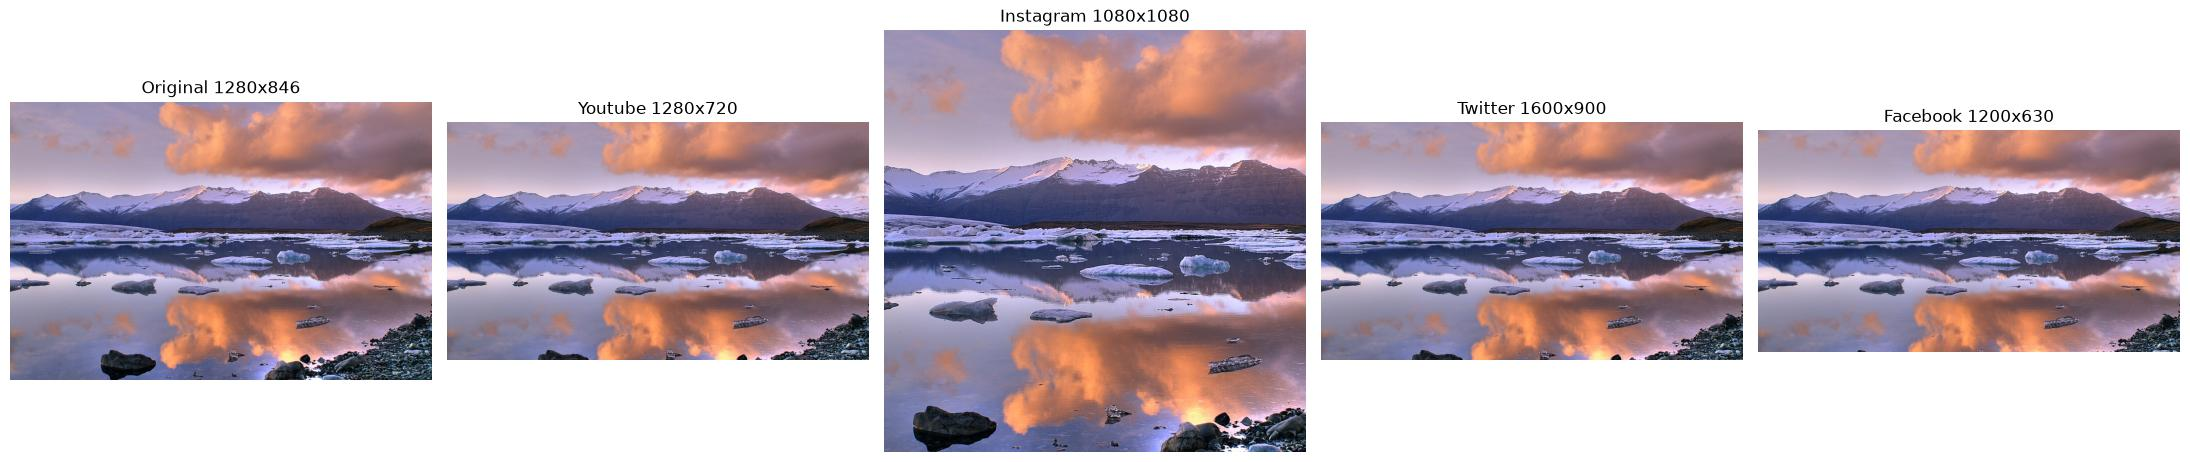

In [6]:
fig, ejes = plt.subplots(1, 5, figsize=(22, 5))
ejes[0].imshow(original)
ejes[0].set_title(f"Original {original.size[0]}x{original.size[1]}")
for eje, (red, img) in zip(ejes[1:], resultados.items()):
    eje.imshow(img)
    eje.set_title(f"{red} {img.size[0]}x{img.size[1]}")
for eje in ejes:
    eje.axis("off")
plt.tight_layout()
plt.savefig(f"{GEN}/1_paisaje_todas_las_redes.png", dpi=100, bbox_inches="tight")
plt.show()

### Comparación de los modos `recortar` y `ajustar`

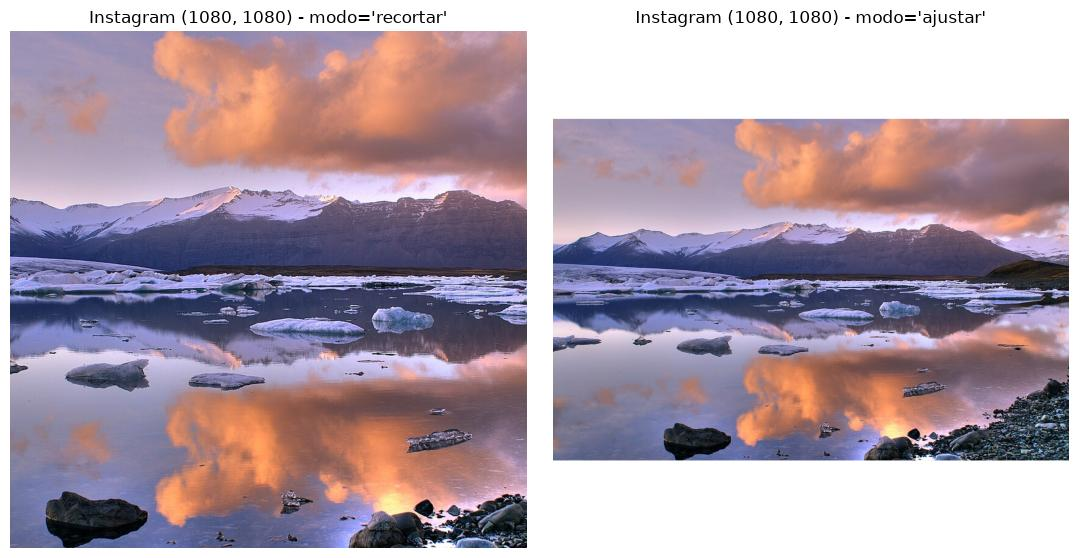

In [7]:
recortada = fotoapp.redimensionar_para_red(ruta_paisaje, "Instagram", modo="recortar")
ajustada = fotoapp.redimensionar_para_red(ruta_paisaje, "Instagram", modo="ajustar",
                                          ruta_salida=f"{GEN}/1_paisaje_instagram_ajustar.jpg")
fig, ejes = plt.subplots(1, 2, figsize=(11, 5.5))
for eje, img, titulo in zip(ejes, [recortada, ajustada], ["modo='recortar'", "modo='ajustar'"]):
    eje.imshow(img)
    eje.set_title(f"Instagram {img.size} - {titulo}")
    eje.axis("off")
plt.tight_layout()
plt.savefig(f"{GEN}/1_modos_recortar_vs_ajustar.png", dpi=100, bbox_inches="tight")
plt.show()

### Lectura desde una URL

La misma función acepta una URL (y también una ruta de Google Drive montado). Probamos descargando la foto del paisaje desde nuestro repositorio en GitHub (un enlace estable) y la mostramos con `mostrar=True`.

In [ ]:
URL_FOTO = ("https://raw.githubusercontent.com/SofiMartin/proyecto2-python-avanzado/master/"
            "proyecto2-python-avanzado/parte1_fotoapp/imagenes/originales/paisaje_islandia.jpg")
foto_url_yt = fotoapp.redimensionar_para_red(URL_FOTO, "youtube", ruta_salida=f"{GEN}/1_url_paisaje_youtube.jpg",
                                             mostrar=True)

### Validaciones con excepciones

La función valida los datos de entrada y lanza excepciones claras (definidas en `fotoapp.py`):

In [ ]:
pruebas = [
    ("Red social inexistente", lambda: fotoapp.redimensionar_para_red(ruta_paisaje, "TikTok")),
    ("Archivo inexistente", lambda: fotoapp.redimensionar_para_red("no_existe.jpg", "Instagram")),
    ("Archivo que no es imagen", lambda: fotoapp.redimensionar_para_red("fotoapp.py", "Instagram")),
    ("Drive sin montar", lambda: fotoapp.redimensionar_para_red("/content/drive/MyDrive/foto.jpg", "Facebook")),
    ("URL inválida", lambda: fotoapp.redimensionar_para_red("https://example.com/no-existe.jpg", "Youtube")),
]
for descripcion, prueba in pruebas:
    try:
        prueba()
        print(f"{descripcion}: no lanzó excepción")
    except (ValueError, FileNotFoundError) as error:
        print(f"{descripcion:25s} -> {type(error).__name__}: {error}")

In [10]:
# Mayúsculas, espacios y alias también se aceptan
for palabra in ["  INSTAGRAM ", "x", "Fb"]:
    print(repr(palabra), "->", fotoapp.normalizar_red(palabra))

'  INSTAGRAM ' -> instagram
'x' -> twitter
'Fb' -> facebook


## 2. Ajuste de contraste con el histograma (ecualización)

El histograma cuenta cuántos píxeles hay de cada nivel de brillo (0 = negro, 255 = blanco). Una foto **oscura** tiene casi todos sus píxeles amontonados a la izquierda, y una foto con **exceso de luz**, a la derecha. En los dos casos se usa solo una parte del rango 0-255, y por eso se ven con poco contraste.

**Ecualizar** es redistribuir esos niveles para que ocupen todo el rango. Usamos `cv2.equalizeHist` de OpenCV, que calcula el histograma, la distribución acumulada y reasigna cada nivel de brillo.

`equalizeHist` solo funciona en escala de grises. Por eso, en fotos color, ecualizamos solo el **brillo** (canal Y de YCrCb) y dejamos los colores como están. Así mejora el contraste sin cambiar los tonos, cosa que sí pasaría si ecualizáramos R, G y B por separado. Debajo de cada foto se ve su histograma: después de ecualizar queda repartido en todo el rango 0-255.

### 2.a Foto oscura

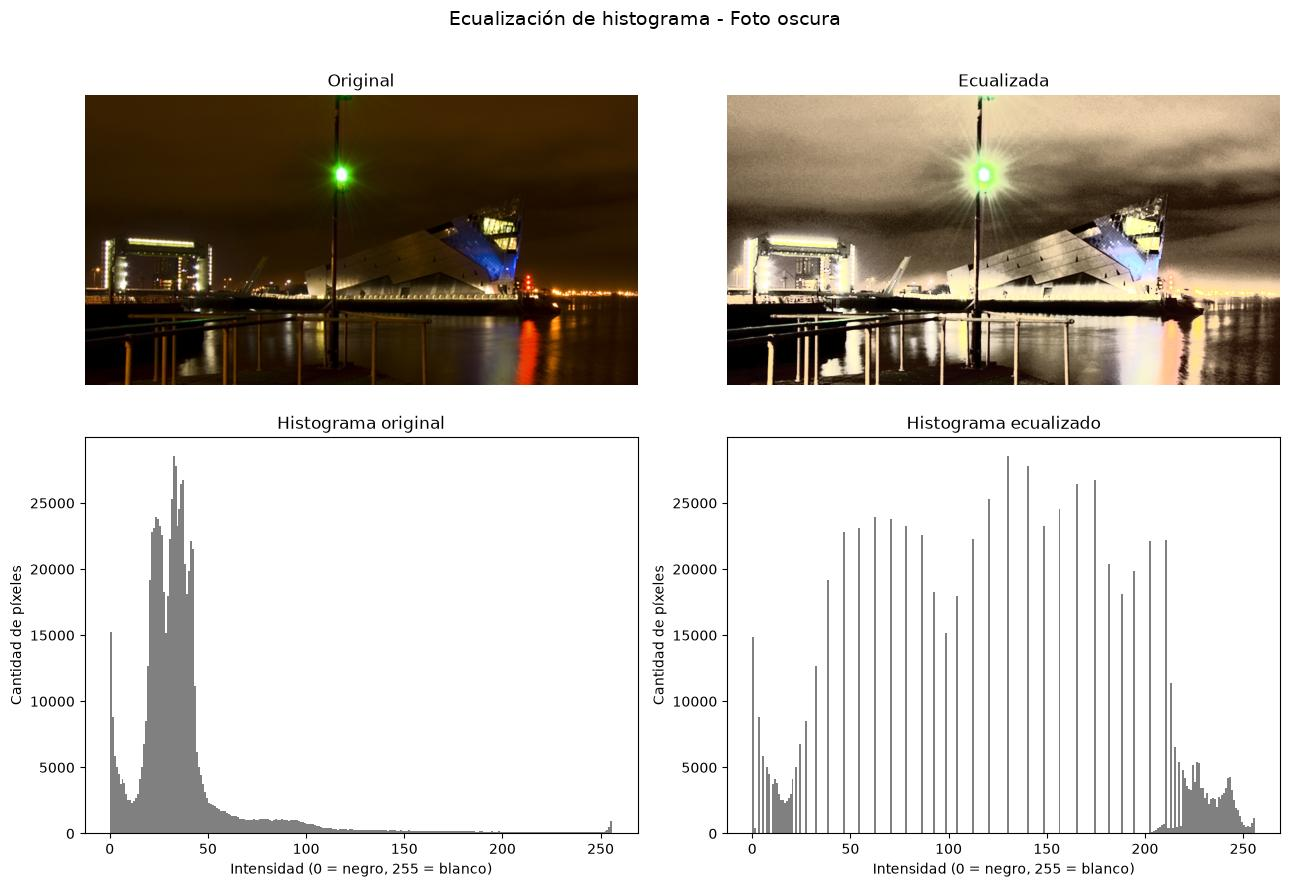

In [11]:
oscura = fotoapp.redimensionar_para_red(f"{ORIG}/noche_oscura.jpg", "Facebook")
oscura_eq = fotoapp.ecualizar_histograma(oscura, ruta_figura=f"{GEN}/2_ecualizacion_foto_oscura.png",
                                         titulo="Foto oscura")

### 2.b Foto con exceso de luz

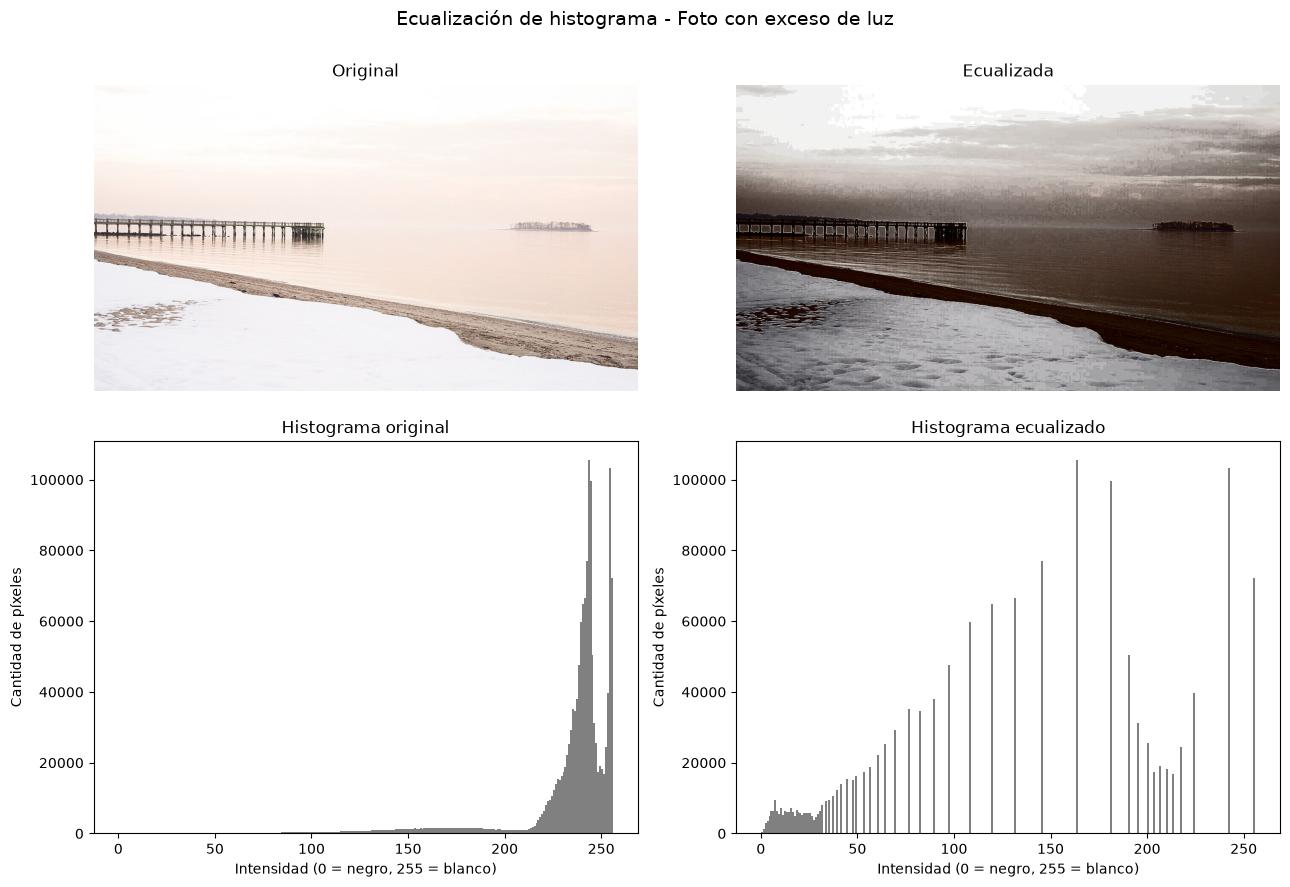

In [12]:
clara = fotoapp.redimensionar_para_red(f"{ORIG}/playa_sobreexpuesta.jpg", "Twitter")
clara_eq = fotoapp.ecualizar_histograma(clara, ruta_figura=f"{GEN}/2_ecualizacion_foto_con_exceso_de_luz.png",
                                        titulo="Foto con exceso de luz")

### 2.c Extra: foto lavada por la niebla (bajo contraste)

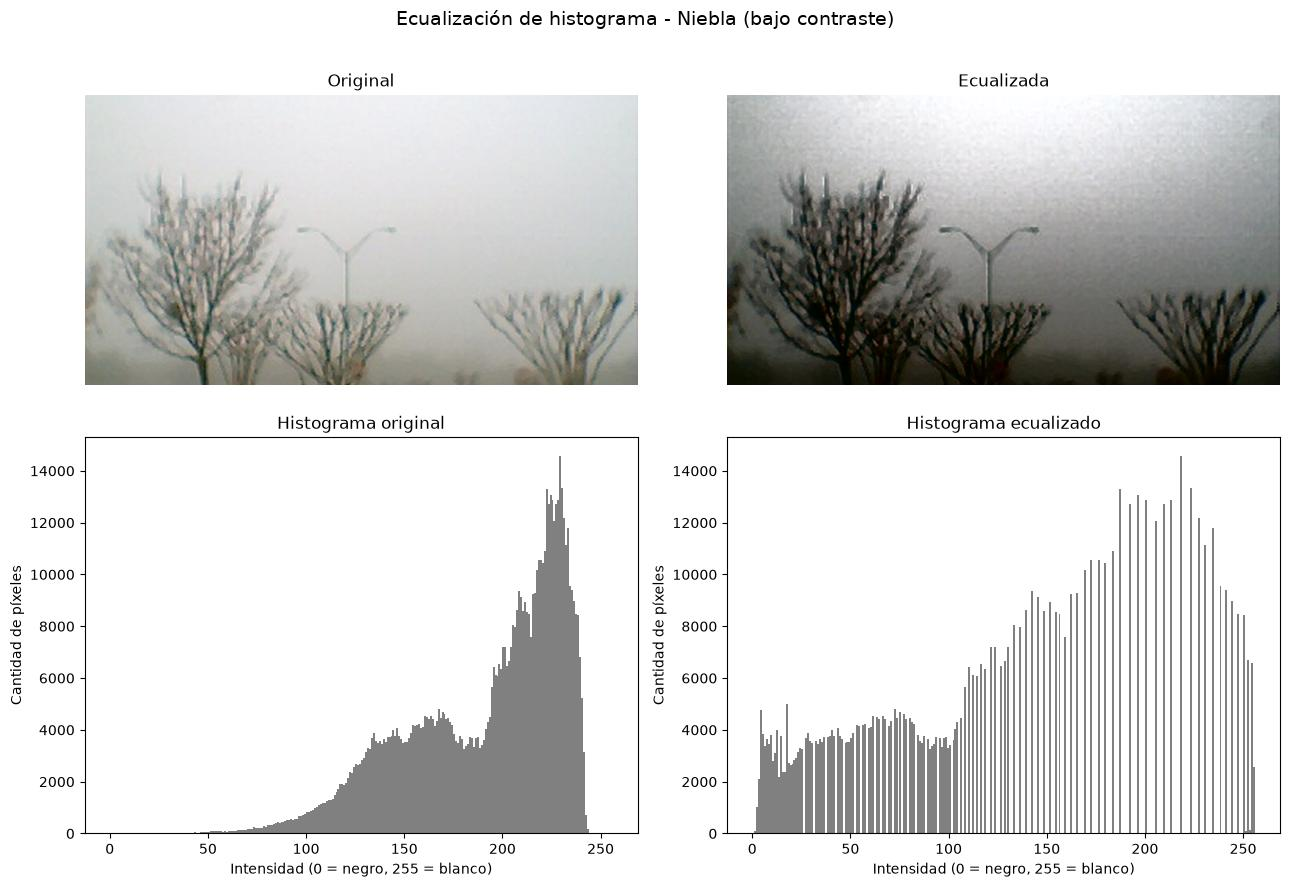

In [13]:
niebla = fotoapp.redimensionar_para_red(f"{ORIG}/niebla_lavada.jpg", "Facebook")
niebla_eq = fotoapp.ecualizar_histograma(niebla, ruta_figura=f"{GEN}/2_ecualizacion_niebla.png",
                                         titulo="Niebla (bajo contraste)")

In [14]:
def estadisticas(img):
    gris = np.asarray(img.convert("L"))
    return gris.mean(), gris.std()

print(f"{'Foto':12s} {'brillo medio':>14s} {'contraste (desvío)':>20s}")
for nombre, antes, despues in [("Oscura", oscura, oscura_eq), ("Exceso luz", clara, clara_eq),
                               ("Niebla", niebla, niebla_eq)]:
    (m0, s0), (m1, s1) = estadisticas(antes), estadisticas(despues)
    print(f"{nombre:12s} {m0:6.1f} -> {m1:5.1f}   {s0:9.1f} -> {s1:5.1f}")

Foto           brillo medio   contraste (desvío)
Oscura         37.6 -> 127.1        32.5 ->  73.8
Exceso luz    232.6 -> 132.1        31.2 ->  75.4
Niebla        190.9 -> 128.8        39.3 ->  74.1


**Observaciones**

- **Foto oscura:** el histograma original estaba concentrado entre 0 y ~50. Después de ecualizar ocupa todo el rango, el brillo medio sube a ~128 y aparecen detalles que no se veían (el cielo, el muelle, los edificios). La contra es que también se amplifica el ruido del sensor y se notan "saltos" de tono: la ecualización estira pocos niveles de gris sobre un rango muy grande.
- **Foto con exceso de luz:** el histograma estaba amontonado en 220-255. La ecualización oscurece los medios tonos y recupera la textura de la arena, el muelle y el horizonte. Lo que estaba completamente blanco (255, "quemado") no se puede recuperar porque esa información no existe en la imagen.
- **Niebla:** es el caso ideal para ecualizar, porque el histograma es angosto pero no está saturado. El contraste (desvío estándar) aumenta mucho y los árboles se ven nítidos.
- El histograma ecualizado tiene forma de "peine" (barras separadas): los niveles originales se reasignan a niveles nuevos, pero no se crean niveles intermedios.

### 2.d Extra: ecualización global vs. CLAHE

`ecualizar_histograma(..., metodo="clahe")` usa **CLAHE** (`cv2.createCLAHE`): en lugar de ecualizar con un único histograma para toda la foto, lo hace por zonas (cuadrículas de 8×8) y limita cuánto se puede estirar el contraste. Así evita el exceso de contraste y amplifica menos el ruido, que era el problema de la foto oscura con el método global.

In [ ]:
oscura_clahe = fotoapp.ecualizar_histograma(oscura, ruta_figura=f"{GEN}/2_ecualizacion_foto_oscura_clahe.png",
                                            titulo="Foto oscura (CLAHE)", metodo="clahe")

print(f"{'Método':10s} {'brillo medio':>14s} {'contraste (desvío)':>20s}")
for nombre, img in [("Original", oscura), ("Global", oscura_eq), ("CLAHE", oscura_clahe)]:
    media, desvio = estadisticas(img)
    print(f"{nombre:10s} {media:14.1f} {desvio:20.1f}")

try:
    fotoapp.ecualizar_histograma(oscura, metodo="otro", mostrar=False)
except ValueError as error:
    print("ValueError:", error)

In [15]:
# Las funciones de edición validan que la imagen haya sido cargada con la función 1
try:
    fotoapp.ecualizar_histograma(None)
except fotoapp.ImagenNoCargadaError as error:
    print("ImagenNoCargadaError:", error)

ImagenNoCargadaError: No hay ninguna imagen cargada. Primero leé la foto con la opción 1 (redimensionar_para_red).


## 3. Los 9 filtros de Pillow

`aplicar_filtro(imagen, filtro)` acepta el **nombre** del filtro o el **número** que elige el usuario:

In [16]:
print(fotoapp.listar_filtros())

  1. Blur
  2. Contour
  3. Detail
  4. Edge Enhance
  5. Edge Enhance More
  6. Emboss
  7. Find Edges
  8. Sharpen
  9. Smooth


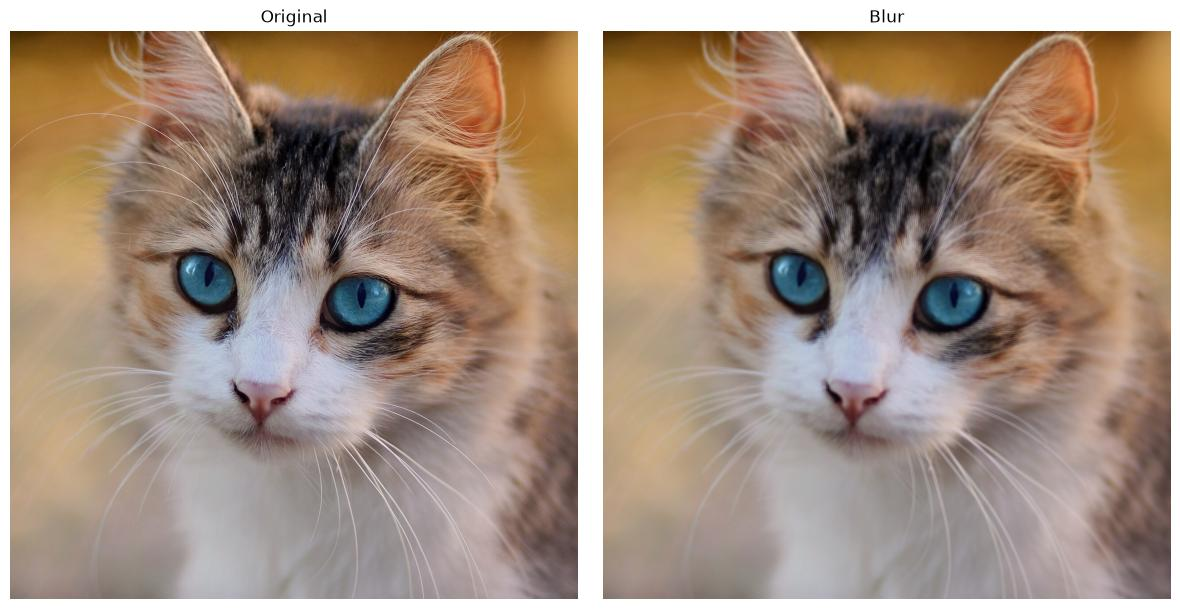

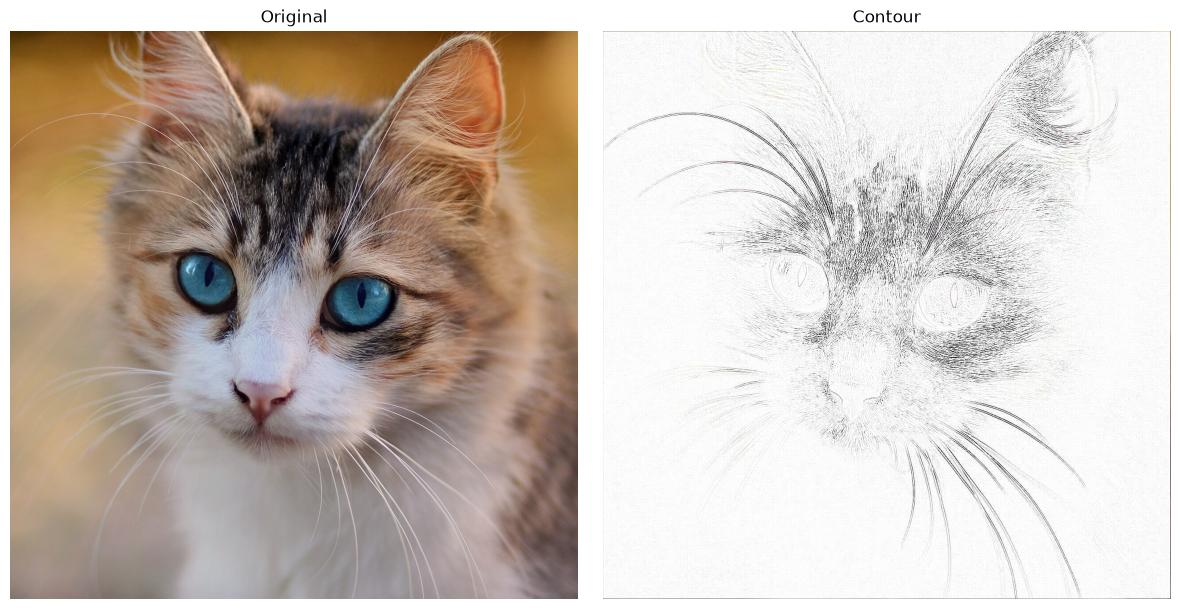

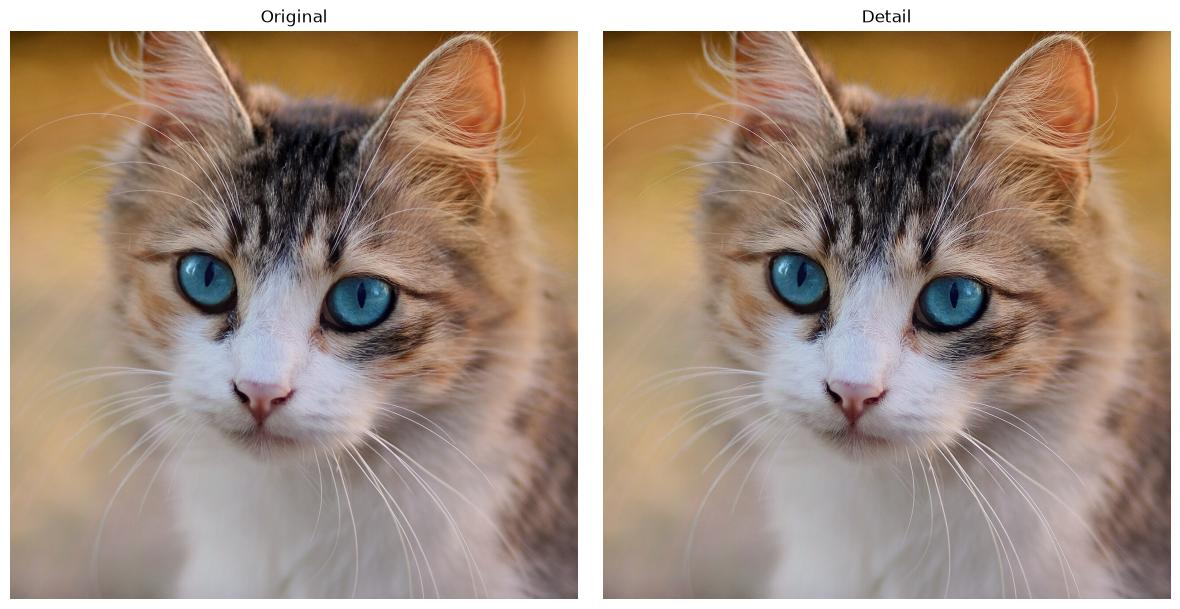

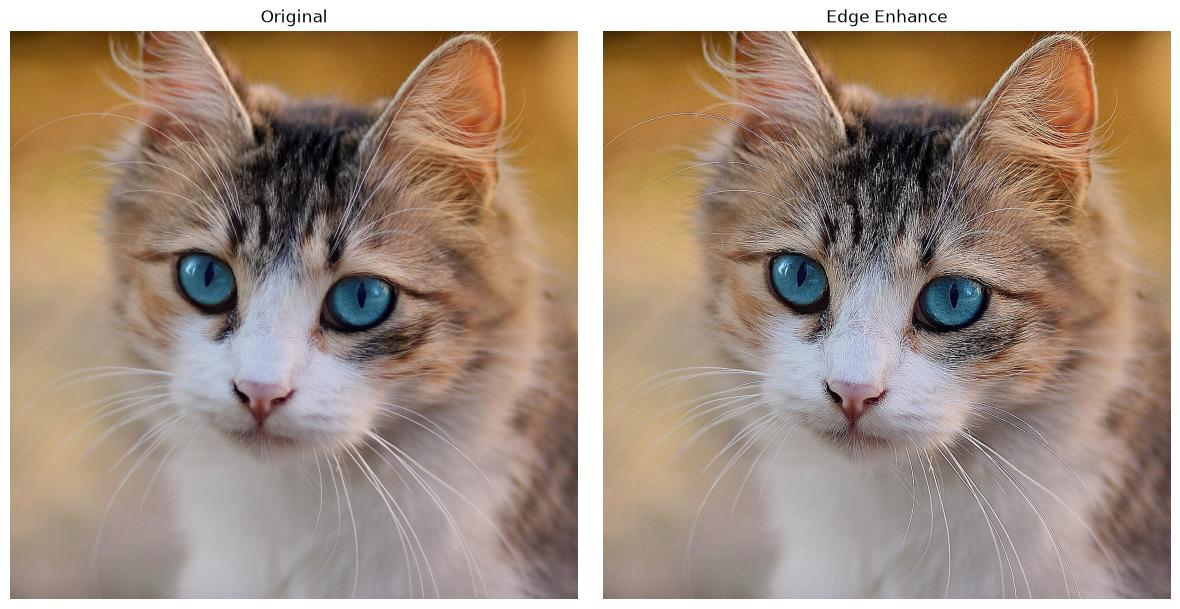

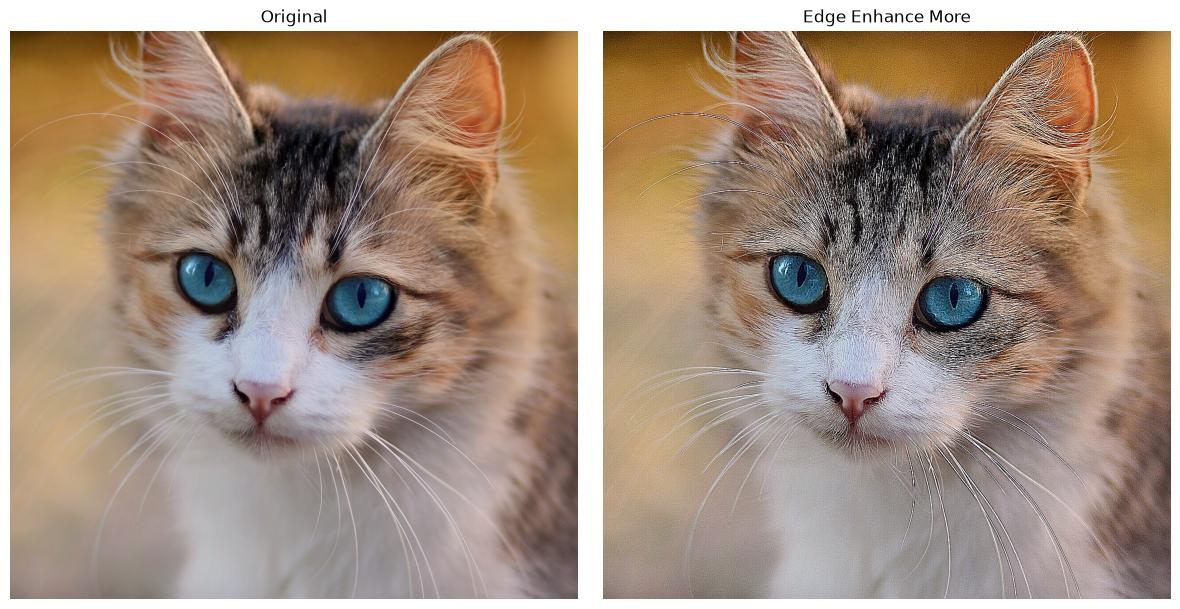

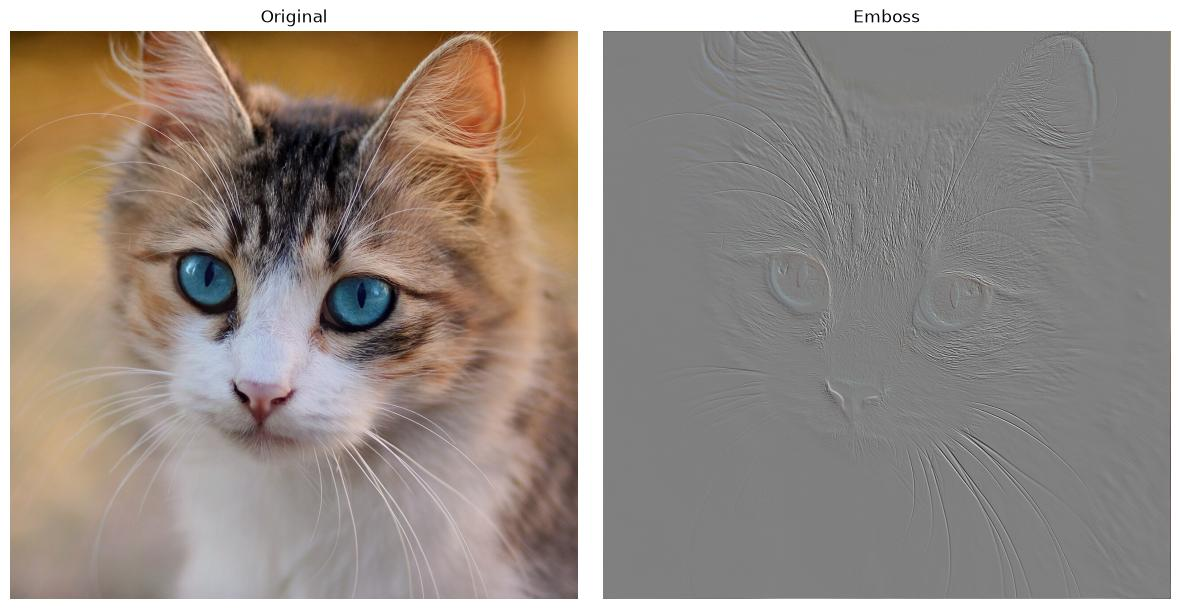

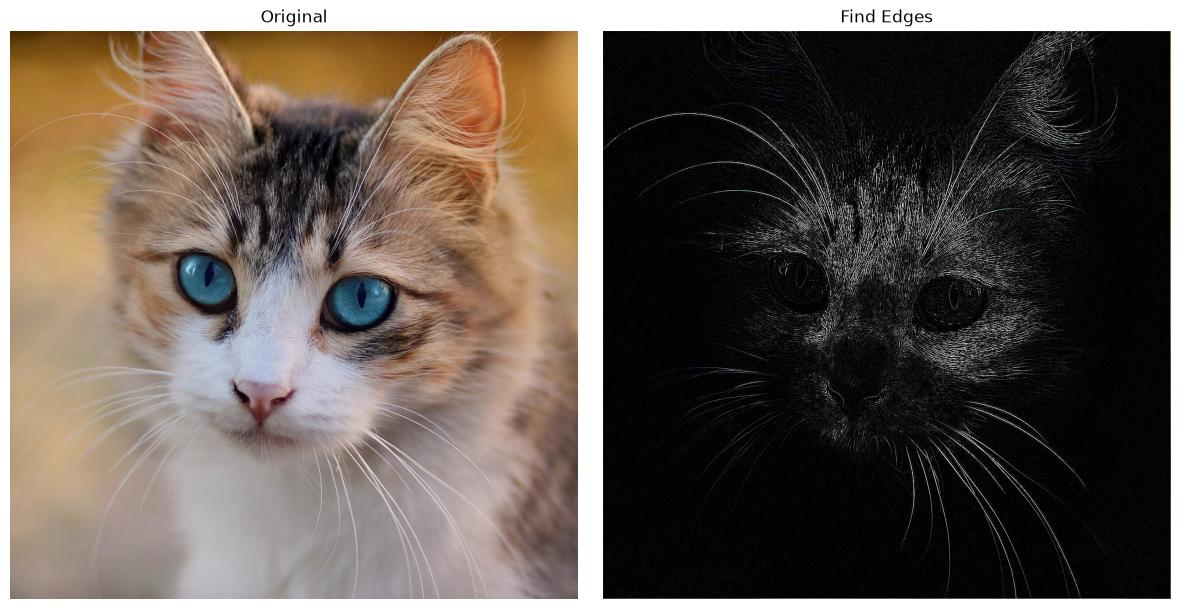

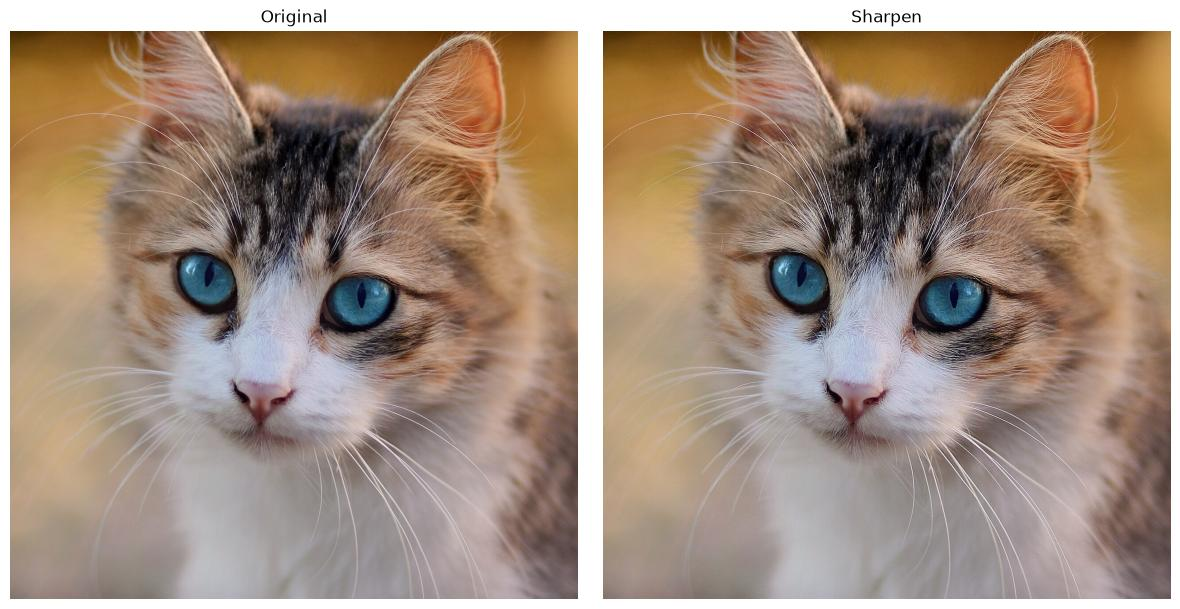

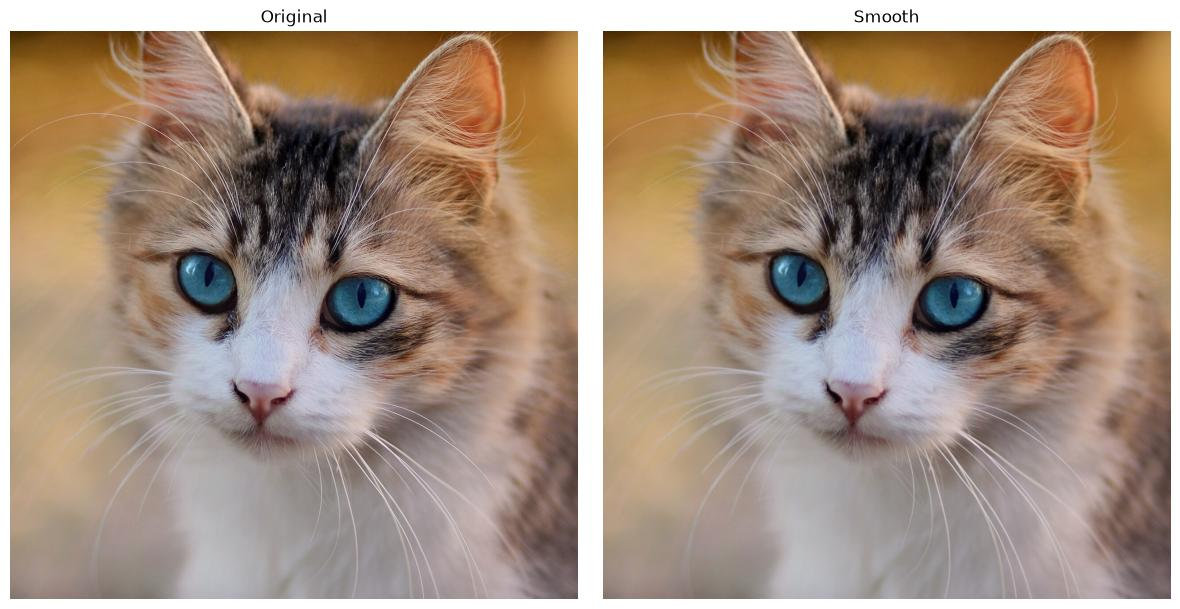

In [17]:
gato = fotoapp.redimensionar_para_red(f"{ORIG}/gato.jpg", "Instagram")
filtradas = {}
for numero, (nombre, _) in fotoapp.FILTROS.items():
    archivo = f"{GEN}/3_filtro_{numero}_{nombre.lower().replace(' ', '_')}.png"
    filtradas[nombre] = fotoapp.aplicar_filtro(gato, nombre, ruta_figura=archivo)

### Comparación de los 9 filtros

Los filtros de Pillow son **convoluciones con núcleos chicos (3×3 o 5×5)**. En una foto de 1080×1080 algunos efectos (Blur, Smooth, Sharpen, Detail) son sutiles cuando se ve la foto entera. Por eso además comparamos un **recorte ampliado** de la zona del ojo:

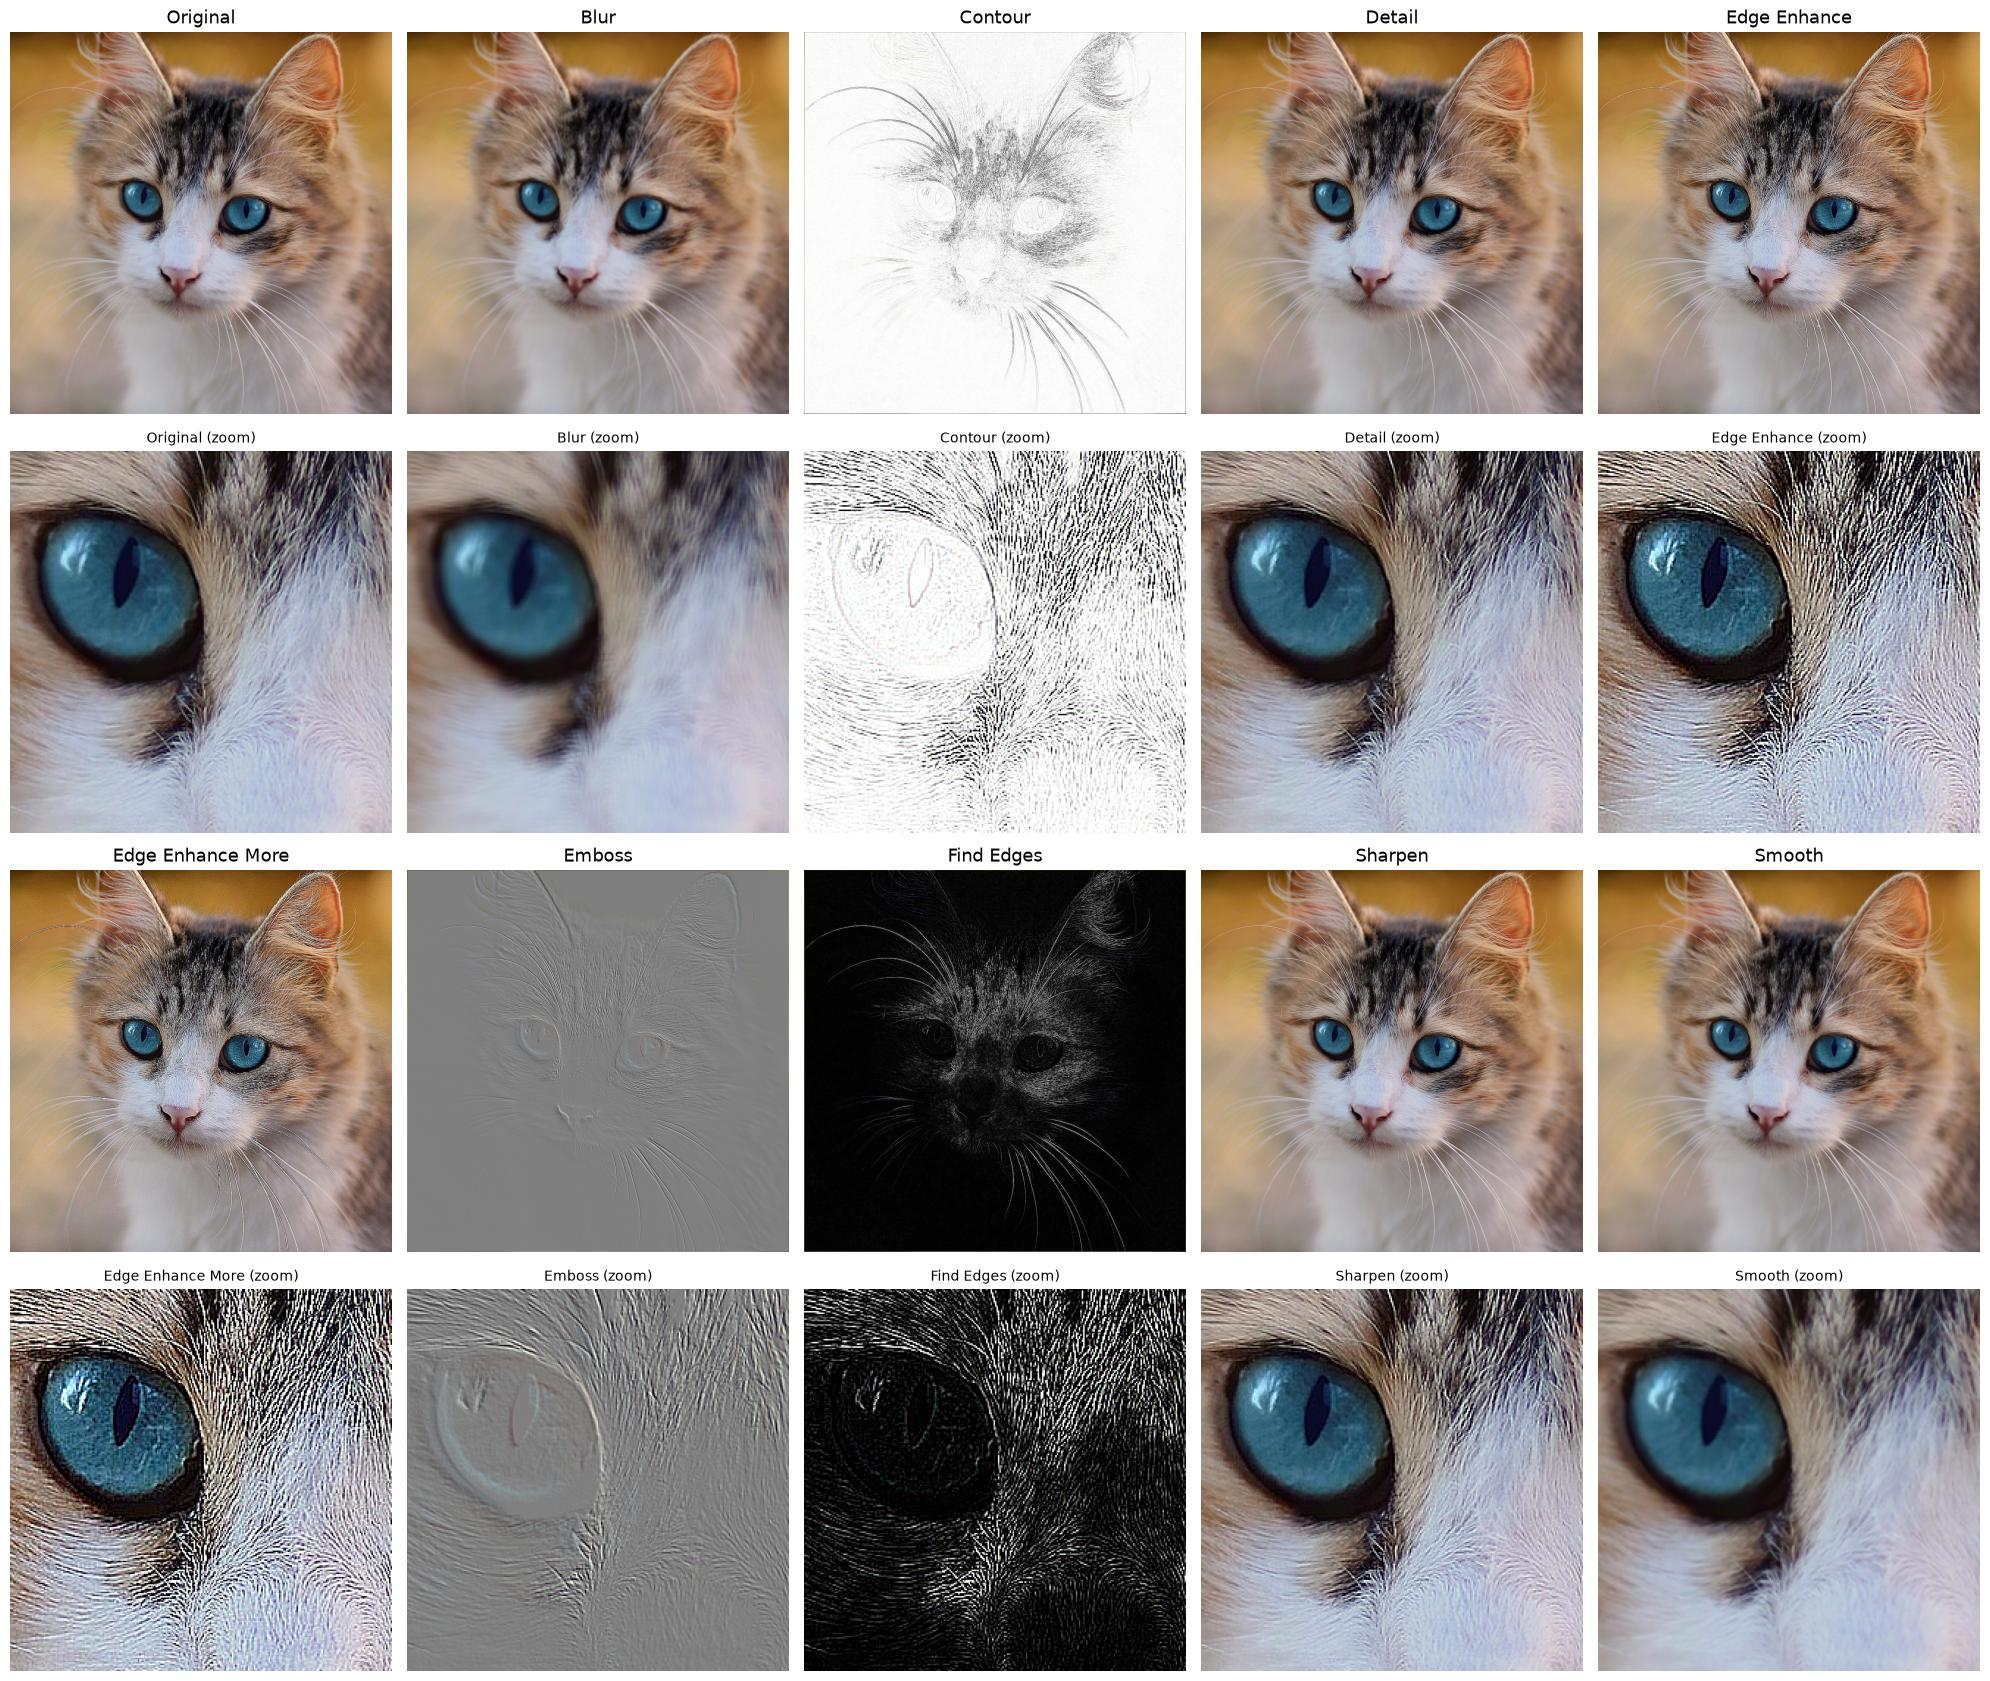

In [18]:
recorte = (300, 380, 560, 640)  # (izq, arriba, der, abajo) alrededor del ojo
paneles = [("Original", gato)] + list(filtradas.items())
# Para cada foto: imagen completa arriba y su recorte ampliado abajo
fig, ejes = plt.subplots(4, 5, figsize=(20, 17))
for i, (titulo, img) in enumerate(paneles):
    fila, col = divmod(i, 5)
    ejes[fila * 2, col].imshow(img)
    ejes[fila * 2, col].set_title(titulo, fontsize=13)
    ejes[fila * 2 + 1, col].imshow(img.crop(recorte))
    ejes[fila * 2 + 1, col].set_title(f"{titulo} (zoom)", fontsize=10)
for eje in ejes.ravel():
    eje.axis("off")
plt.tight_layout()
plt.savefig(f"{GEN}/3_comparativa_9_filtros.png", dpi=90, bbox_inches="tight")
plt.show()

| # | Filtro | ¿Qué hace? | Resultado en la foto del gato |
|---|---|---|---|
| 1 | **Blur** | Promedia cada píxel con sus vecinos en un entorno de 5×5 (desenfoque). | Suaviza el pelaje y se pierde nitidez en los bigotes. |
| 2 | **Contour** | Detecta los cambios bruscos de intensidad y los dibuja como líneas oscuras sobre un fondo claro. | Parece un dibujo a lápiz; resalta el contorno de los ojos y del pelaje. |
| 3 | **Detail** | Realce suave de los detalles finos. | Muy parecido al original, con el pelaje apenas más definido. |
| 4 | **Edge Enhance** | Suma a la imagen sus bordes para acentuarlos. | Bordes más marcados sin cambiar los colores. |
| 5 | **Edge Enhance More** | Igual que el anterior pero más fuerte. | Muy nítido, pero empiezan a aparecer ruido y "granulado" en el pelaje. |
| 6 | **Emboss** | Relieve: resalta los bordes en una dirección diagonal sobre un fondo gris. | Efecto de grabado o moneda; se pierde el color. |
| 7 | **Find Edges** | Deja solo los bordes (claros) sobre un fondo negro. | Se ven los contornos del gato como un dibujo luminoso. |
| 8 | **Sharpen** | Enfoca: aumenta la diferencia de cada píxel con sus vecinos. | Bigotes y ojos más nítidos que en el original. |
| 9 | **Smooth** | Suavizado leve (más leve que Blur). | Reduce un poco el ruido; casi no se nota en la foto completa. |

**Conclusión:** los filtros forman dos familias opuestas. **Blur** y **Smooth** son *pasa-bajos*: eliminan detalle y ruido. **Sharpen**, **Detail** y los **Edge Enhance** son *pasa-altos*: refuerzan los detalles, y también el ruido. **Contour**, **Find Edges** y **Emboss** no "mejoran" la foto sino que la transforman en una representación de sus bordes: son el punto de partida del boceto del punto 4.

In [19]:
# El usuario también puede elegir el filtro por número, y un número inválido lanza una excepción
_ = fotoapp.aplicar_filtro(gato, 6, mostrar=False)
for invalido in [12, "Sepia"]:
    try:
        fotoapp.aplicar_filtro(gato, invalido)
    except fotoapp.FiltroInvalidoError as error:
        print("FiltroInvalidoError:", str(error).splitlines()[0])

FiltroInvalidoError: Filtro '12' inválido. Elegí un número o nombre de:
FiltroInvalidoError: Filtro 'Sepia' inválido. Elegí un número o nombre de:


## 4. Boceto de líneas a partir de un retrato

Usamos un retrato con fondo simple. La función `boceto(imagen, tecnica, **parametros)` convierte la foto a escala de grises, la suaviza con un desenfoque gaussiano (para que el ruido y la textura de la piel no generen bordes falsos) y aplica una de estas técnicas:

| Técnica | Idea | Parámetros principales |
|---|---|---|
| `umbral` | **Umbralización adaptativa**: cada píxel se compara con el promedio de su vecindario. Si es más oscuro que ese promedio menos `c`, se pinta de negro. | `bloque` (tamaño del vecindario), `c` |
| `sobel` | **Gradiente de Sobel**: derivadas en x e y. Su magnitud es alta donde hay un borde; nos quedamos con los píxeles que superan un `umbral`. | `ksize`, `umbral` |
| `laplaciano` | **Laplaciano** (segunda derivada): responde a cambios bruscos en cualquier dirección. | `ksize`, `umbral` |
| `canny` | **Canny**: gradiente + supresión de no máximos + umbral con histéresis. Da líneas finas y continuas. | `umbral_bajo`, `umbral_alto` |

En todas las técnicas el resultado son **líneas negras sobre fondo blanco**, y el parámetro `grosor` permite engrosar las líneas.

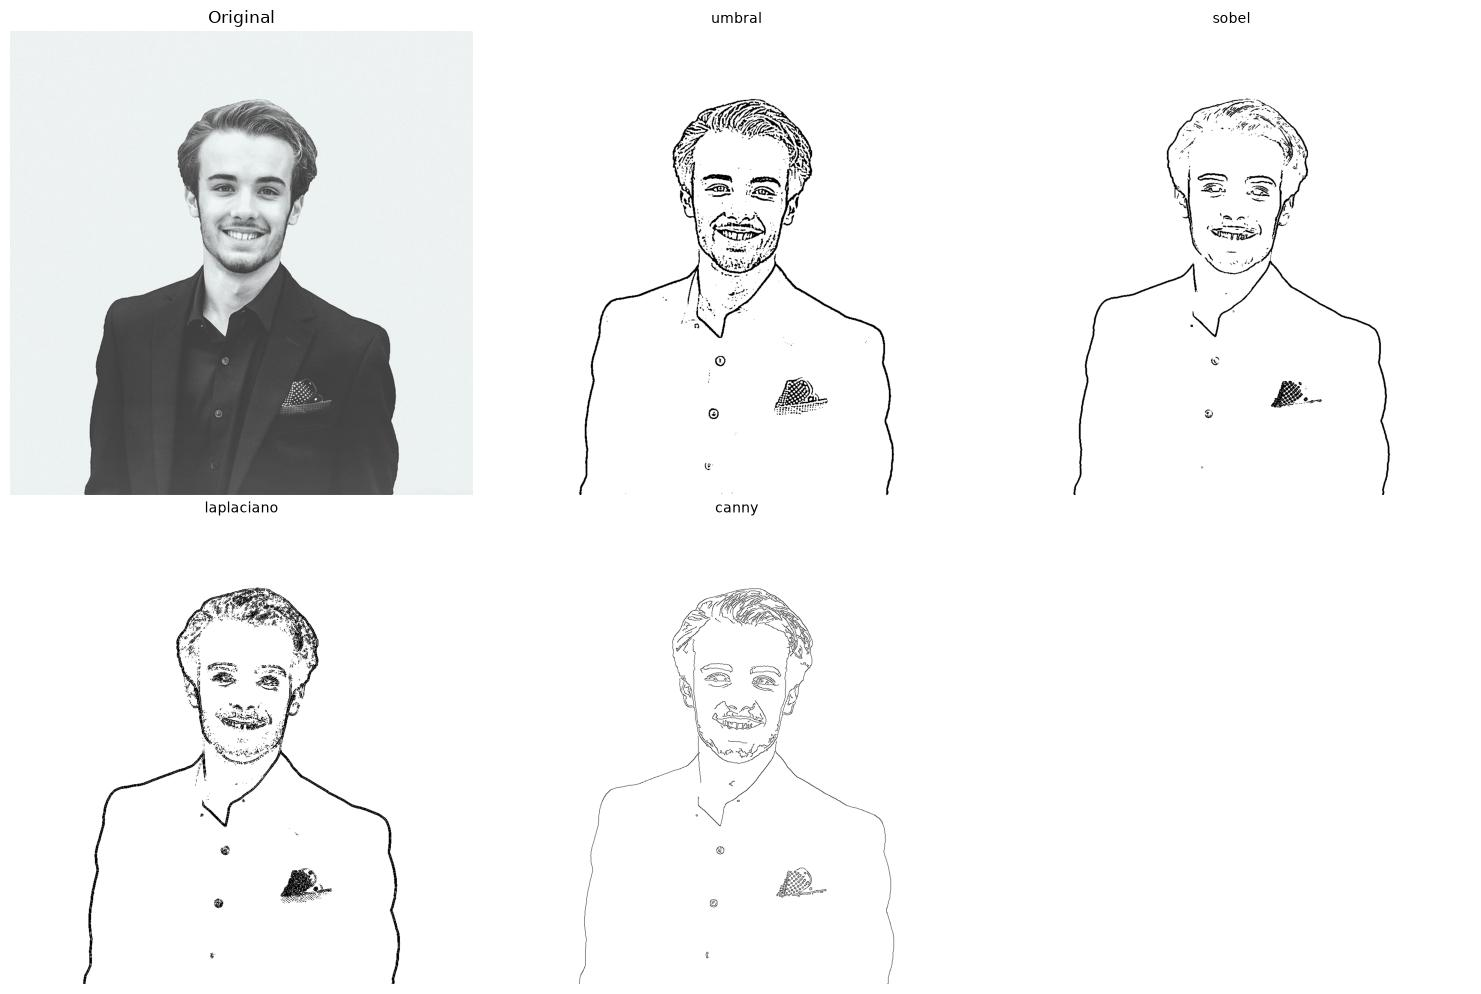

In [20]:
retrato = fotoapp.redimensionar_para_red(f"{ORIG}/retrato.jpg", "Instagram")
tecnicas_por_defecto = [{"tecnica": t} for t in fotoapp.TECNICAS_BOCETO]
_ = fotoapp.comparar_bocetos(retrato, tecnicas_por_defecto, ruta_figura=f"{GEN}/4_comparativa_tecnicas.png")

### Ajuste de parámetros: Canny

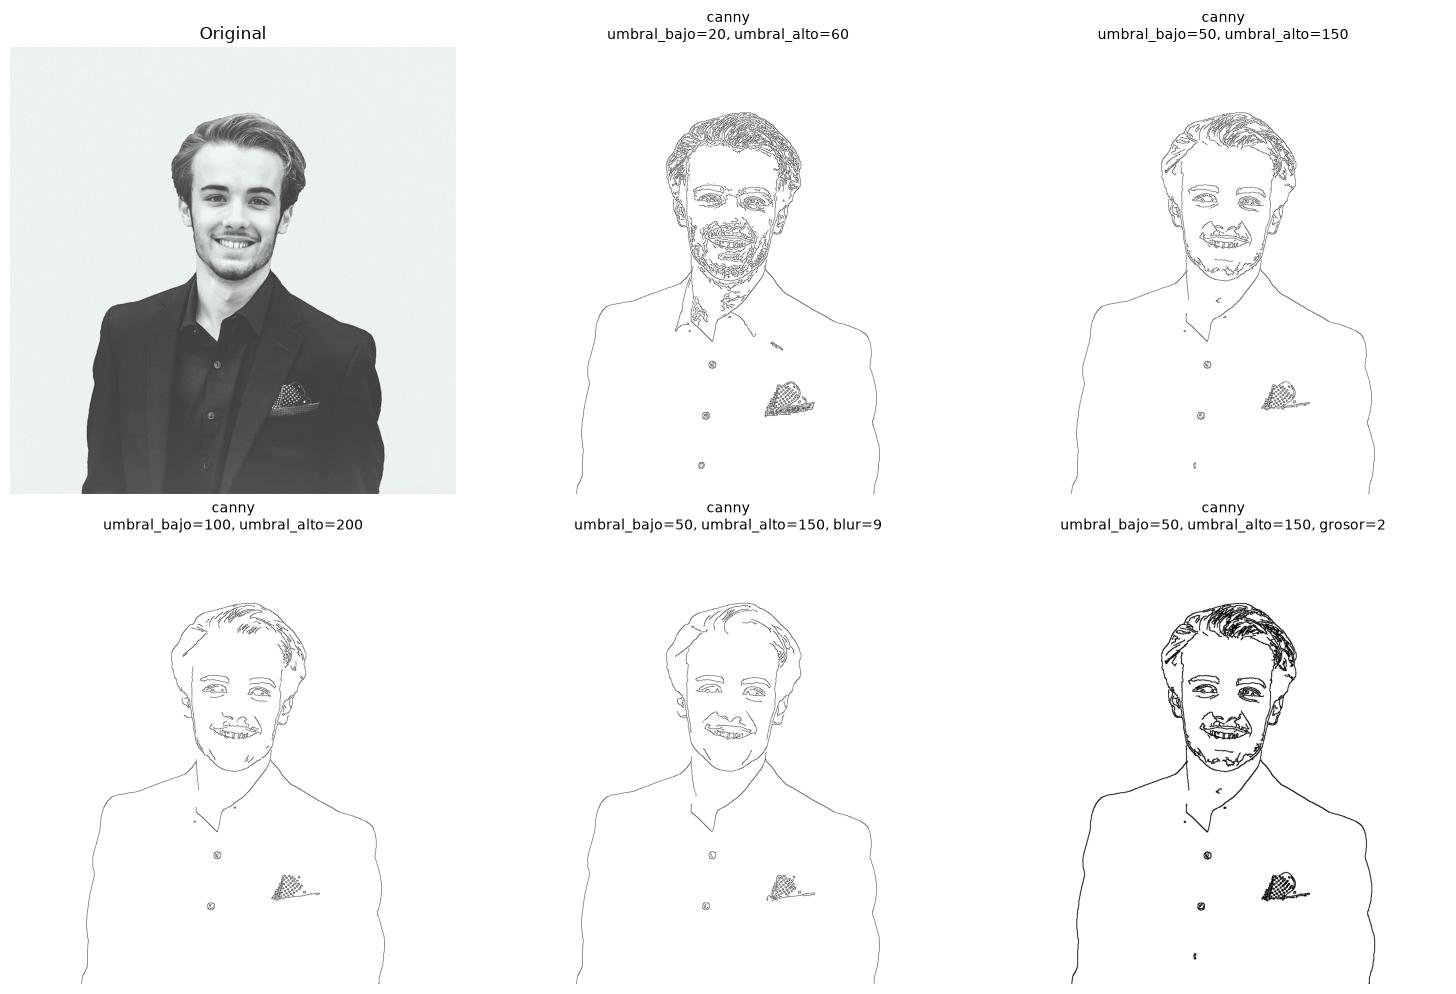

In [21]:
configs_canny = [
    {"tecnica": "canny", "umbral_bajo": 20, "umbral_alto": 60},
    {"tecnica": "canny", "umbral_bajo": 50, "umbral_alto": 150},
    {"tecnica": "canny", "umbral_bajo": 100, "umbral_alto": 200},
    {"tecnica": "canny", "umbral_bajo": 50, "umbral_alto": 150, "blur": 9},
    {"tecnica": "canny", "umbral_bajo": 50, "umbral_alto": 150, "grosor": 2},
]
_ = fotoapp.comparar_bocetos(retrato, configs_canny, ruta_figura=f"{GEN}/4_parametros_canny.png")

### Ajuste de parámetros: Sobel y Laplaciano

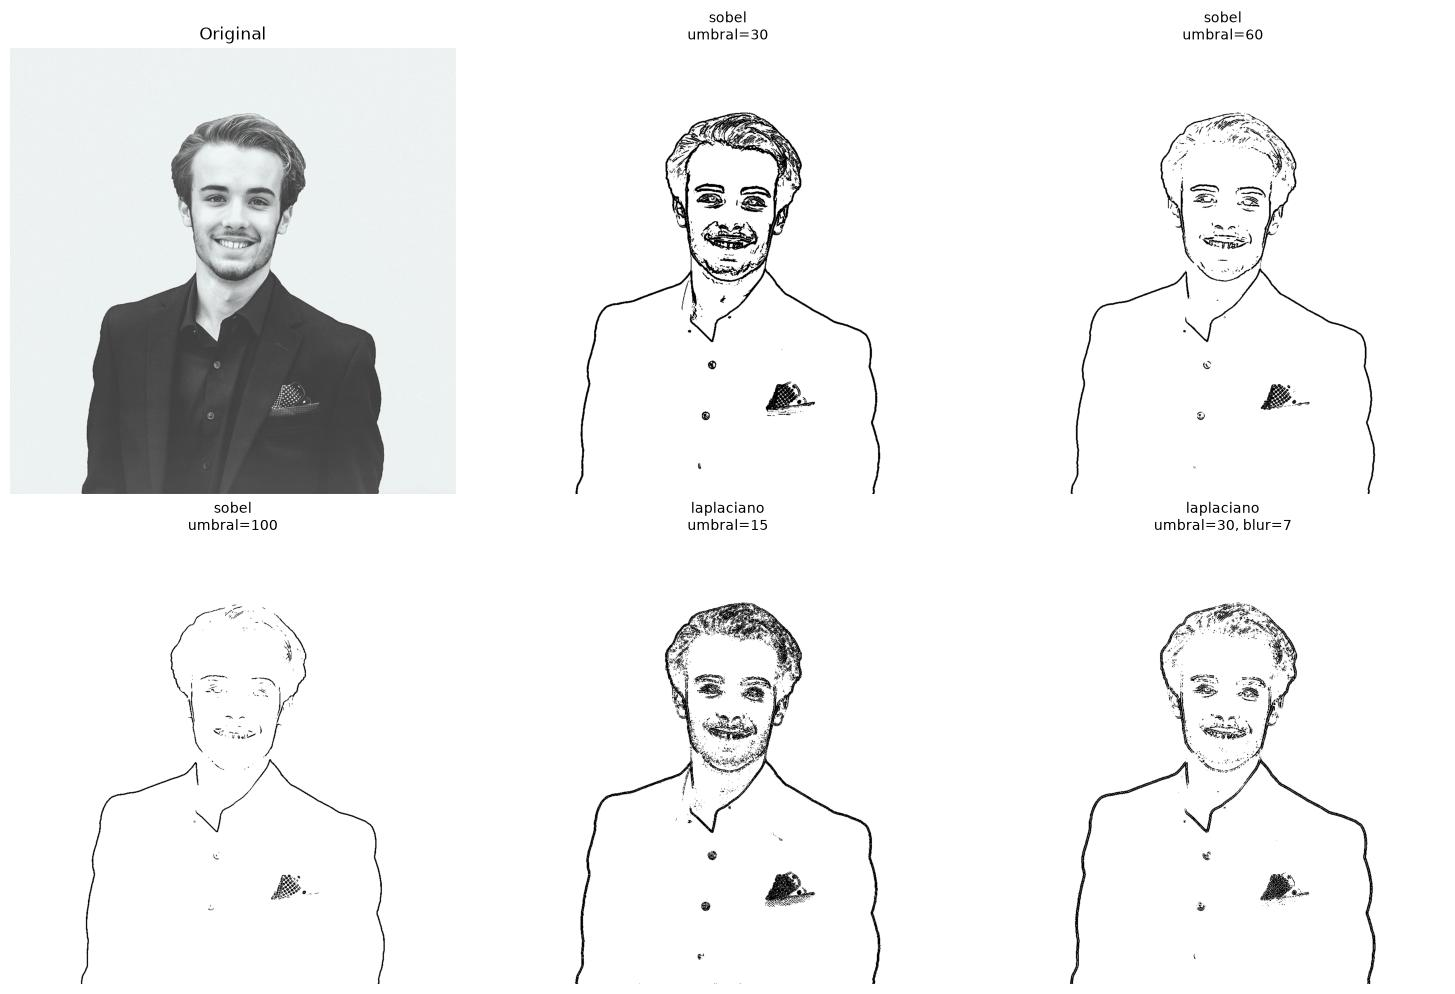

In [22]:
configs_gradiente = [
    {"tecnica": "sobel", "umbral": 30},
    {"tecnica": "sobel", "umbral": 60},
    {"tecnica": "sobel", "umbral": 100},
    {"tecnica": "laplaciano", "umbral": 15},
    {"tecnica": "laplaciano", "umbral": 30, "blur": 7},
]
_ = fotoapp.comparar_bocetos(retrato, configs_gradiente, ruta_figura=f"{GEN}/4_parametros_sobel_laplaciano.png")

### Ajuste de parámetros: umbralización adaptativa

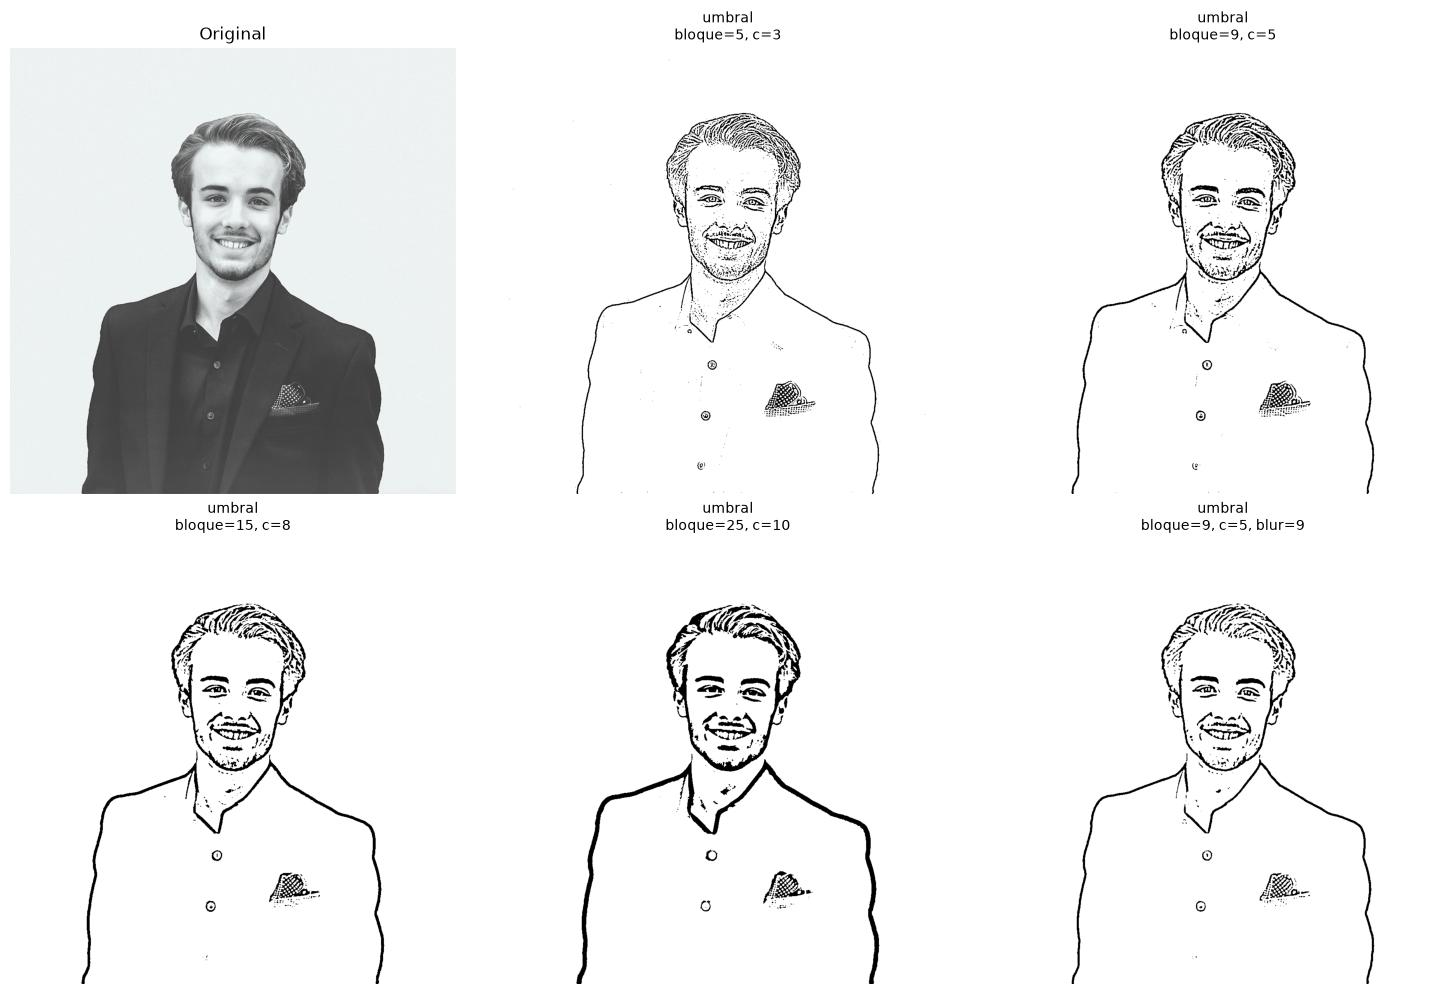

In [23]:
configs_umbral = [
    {"tecnica": "umbral", "bloque": 5, "c": 3},
    {"tecnica": "umbral", "bloque": 9, "c": 5},
    {"tecnica": "umbral", "bloque": 15, "c": 8},
    {"tecnica": "umbral", "bloque": 25, "c": 10},
    {"tecnica": "umbral", "bloque": 9, "c": 5, "blur": 9},
]
_ = fotoapp.comparar_bocetos(retrato, configs_umbral, ruta_figura=f"{GEN}/4_parametros_umbral.png")

### Resultado final elegido

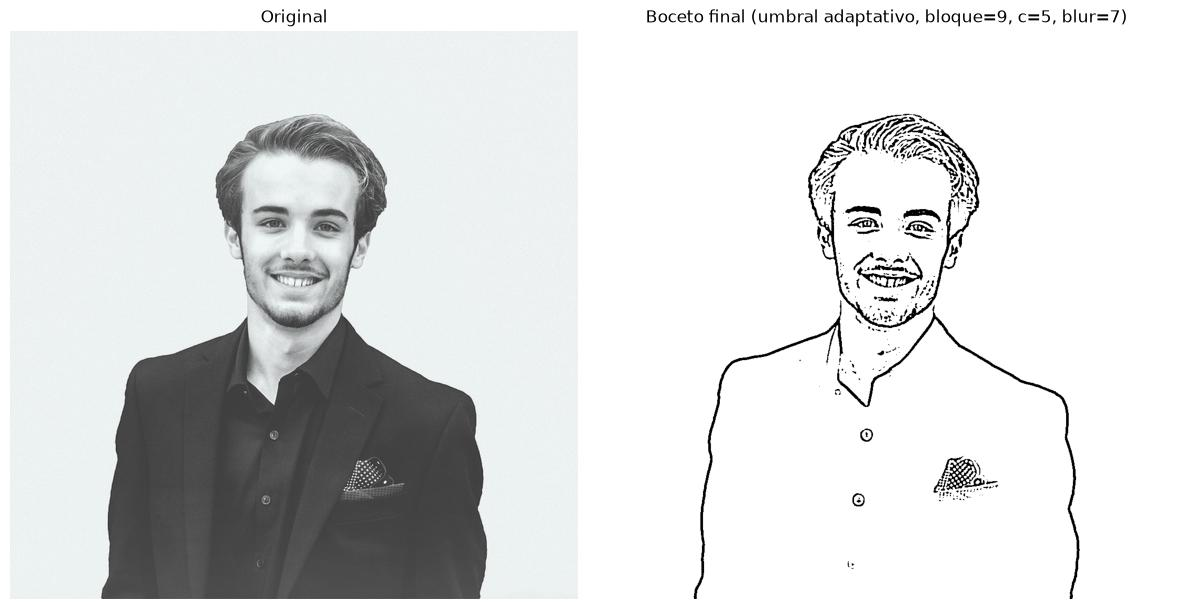

In [24]:
boceto_final = fotoapp.boceto(retrato, "umbral", bloque=9, c=5, blur=7)
boceto_final.save(f"{GEN}/4_boceto_final.png")

fig, ejes = plt.subplots(1, 2, figsize=(12, 6))
ejes[0].imshow(retrato)
ejes[0].set_title("Original")
ejes[1].imshow(boceto_final, cmap="gray")
ejes[1].set_title("Boceto final (umbral adaptativo, bloque=9, c=5, blur=7)")
for eje in ejes:
    eje.axis("off")
plt.tight_layout()
plt.savefig(f"{GEN}/4_boceto_final_comparacion.png", dpi=100, bbox_inches="tight")
plt.show()

**Conclusiones del boceto**

- **Umbral adaptativo**: es el que más se parece a un *boceto a mano*: marca el contorno de la cara, el pelo, los ojos y la sonrisa con trazos de grosor natural. Con `bloque` chico aparecen muchos puntos de textura (piel, barba); con `bloque` y `c` grandes las líneas quedan más gruesas y limpias, pero se pierden detalles.
- **Sobel**: da contornos gruesos y cerrados de la silueta. Con umbral bajo (30) aparece mucha textura del pelo y de la barba; con umbral alto (100) solo queda la silueta exterior.
- **Laplaciano**: al ser una segunda derivada es muy sensible al ruido. Genera puntos en zonas con textura (pelo, barba, pañuelo), por eso conviene suavizar más (`blur` mayor) y subir el umbral.
- **Canny**: da las líneas más finas y continuas, y es el más "técnico". Umbrales bajos (20/60) generan demasiados bordes; altos (100/200) dejan solo los más marcados. 50/150 es un buen equilibrio, y con `grosor=2` el resultado se ve mejor como dibujo.
- El **desenfoque previo** es clave en todas las técnicas: sin él, la textura de la piel y el ruido generan bordes falsos.

## 5. Menú de opciones

`fotoapp.menu()` es el menú interactivo de la app. Para poder probarlo de forma automática en este notebook, el menú recibe un parámetro `entrada` (por defecto es `input`). Acá le pasamos una función que va devolviendo respuestas simuladas y las imprime, como si las hubiera escrito un usuario.

En la simulación probamos que:
- si el usuario intenta editar **sin haber leído una imagen** (opción 3 al principio), el menú lo frena y le indica que use la opción 1;
- una red social inválida se informa sin que el programa se corte;
- después de leer la imagen se pueden encadenar ecualización, filtro y boceto, y guardar el resultado.

> Para usar el menú de verdad, ejecutar `fotoapp.menu()` (en Colab o Jupyter) o `python fotoapp.py` en una terminal.


================ FOTOAPP ================
Imagen actual: ninguna (usá la opción 1)
  1. Leer imagen y redimensionar para una red social
  2. Ajustar contraste (ecualizar histograma)
  3. Aplicar un filtro
  4. Generar boceto (bordes y contornos)
  5. Guardar imagen actual
  0. Salir
Elegí una opción: 3
[!] No hay ninguna imagen cargada. Primero leé la foto con la opción 1 (redimensionar_para_red).

================ FOTOAPP ================
Imagen actual: ninguna (usá la opción 1)
  1. Leer imagen y redimensionar para una red social
  2. Ajustar contraste (ecualizar histograma)
  3. Aplicar un filtro
  4. Generar boceto (bordes y contornos)
  5. Guardar imagen actual
  0. Salir
Elegí una opción: 1
Ruta (archivo, Drive) o URL de la imagen: imagenes/originales/retrato2.jpg
Red social (Youtube / Instagram / Twitter / Facebook): TikTok
Modo [r]ecortar o [a]justar con bandas (Enter = recortar): 
[!] Error: Red social 'TikTok' no soportada. Opciones: Youtube, Instagram, Twitter, Facebook.

=

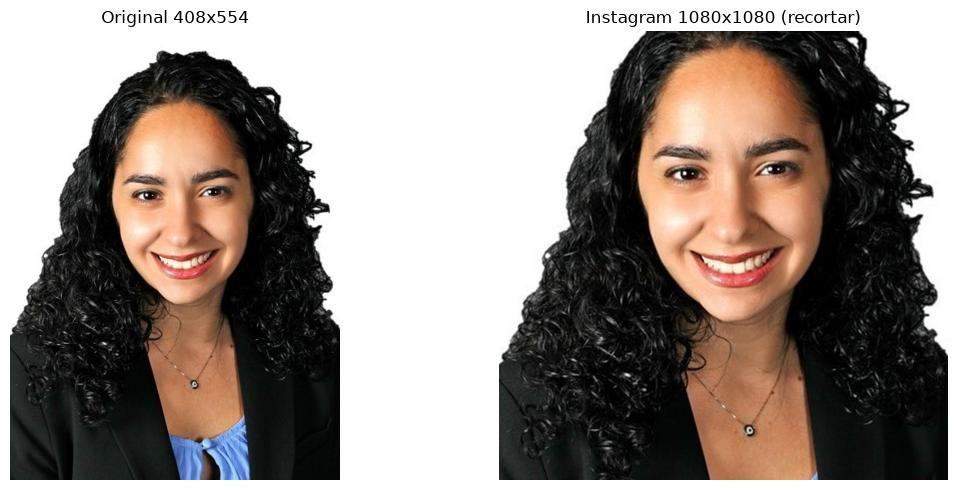

Imagen lista para Instagram: 1080x1080 px
Imagen guardada en imagenes/generadas\instagram_retrato2.jpg

================ FOTOAPP ================
Imagen actual: retrato2.jpg -> Instagram (1080, 1080)
  1. Leer imagen y redimensionar para una red social
  2. Ajustar contraste (ecualizar histograma)
  3. Aplicar un filtro
  4. Generar boceto (bordes y contornos)
  5. Guardar imagen actual
  0. Salir
Elegí una opción: 2


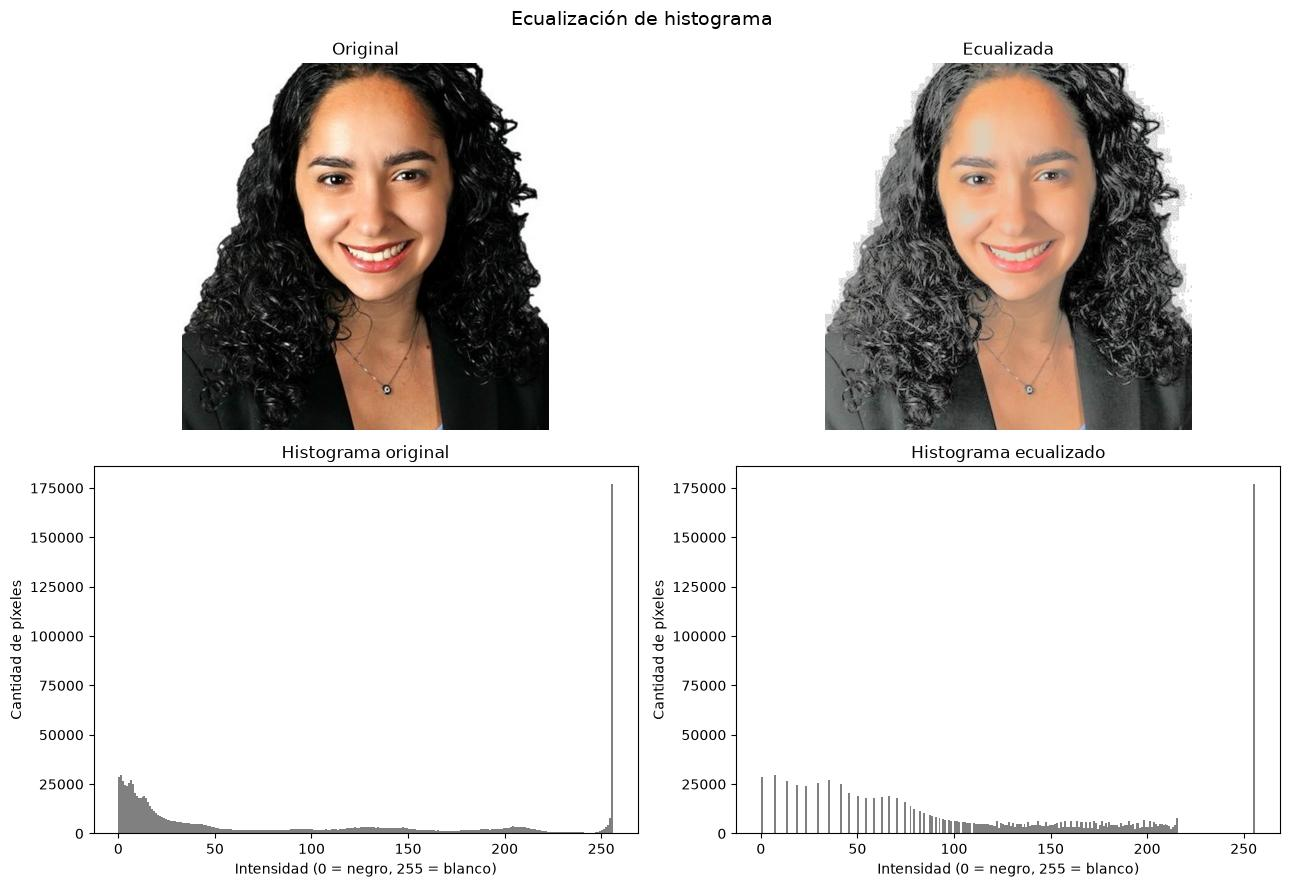

Figura guardada en imagenes/generadas\menu_01_ecualizacion.png
¿Usar la imagen ecualizada como imagen actual? (s/n): s

================ FOTOAPP ================
Imagen actual: retrato2.jpg -> Instagram (1080, 1080) + ecualizada
  1. Leer imagen y redimensionar para una red social
  2. Ajustar contraste (ecualizar histograma)
  3. Aplicar un filtro
  4. Generar boceto (bordes y contornos)
  5. Guardar imagen actual
  0. Salir
Elegí una opción: 3
Filtros disponibles:
  1. Blur
  2. Contour
  3. Detail
  4. Edge Enhance
  5. Edge Enhance More
  6. Emboss
  7. Find Edges
  8. Sharpen
  9. Smooth
Número de filtro (1-9): 8


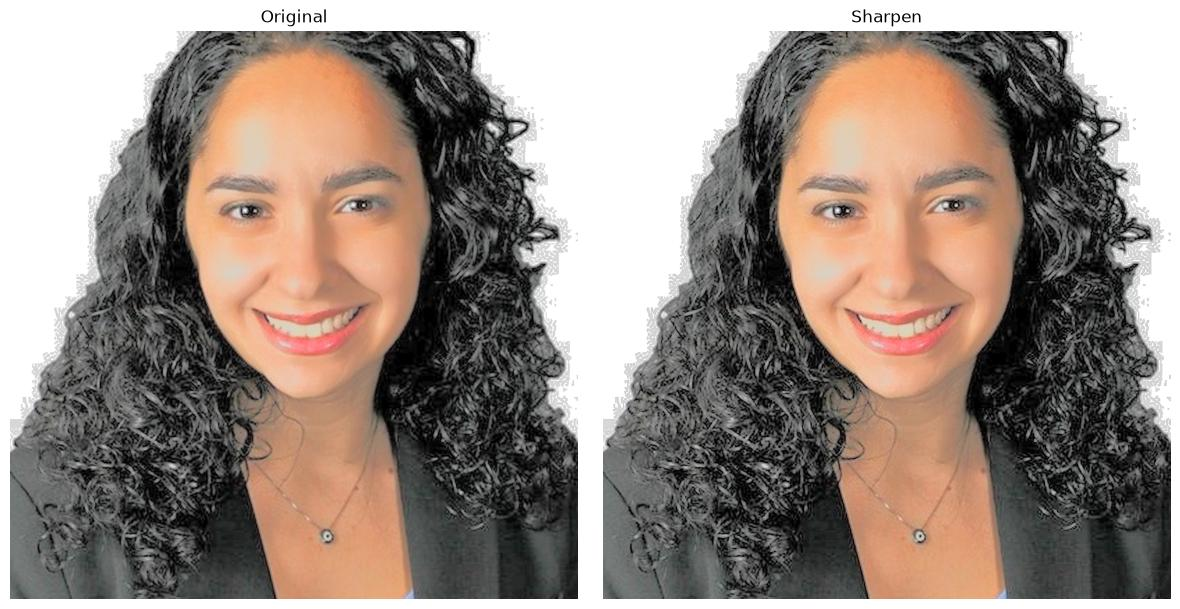

Figura guardada en imagenes/generadas\menu_02_filtro_sharpen.png
¿Usar la imagen con Sharpen como imagen actual? (s/n): s

================ FOTOAPP ================
Imagen actual: retrato2.jpg -> Instagram (1080, 1080) + ecualizada + Sharpen
  1. Leer imagen y redimensionar para una red social
  2. Ajustar contraste (ecualizar histograma)
  3. Aplicar un filtro
  4. Generar boceto (bordes y contornos)
  5. Guardar imagen actual
  0. Salir
Elegí una opción: 4
Técnicas:
  1. umbral
  2. sobel
  3. laplaciano
  4. canny
Número de técnica (Enter = canny): 1


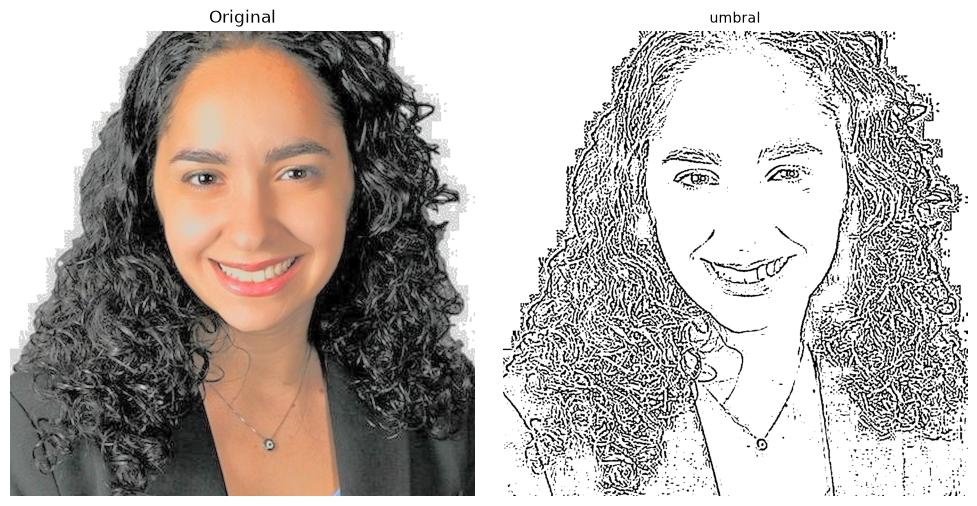

Figura guardada en imagenes/generadas\menu_03_boceto_umbral.png
¿Usar el boceto como imagen actual? (s/n): n

================ FOTOAPP ================
Imagen actual: retrato2.jpg -> Instagram (1080, 1080) + ecualizada + Sharpen
  1. Leer imagen y redimensionar para una red social
  2. Ajustar contraste (ecualizar histograma)
  3. Aplicar un filtro
  4. Generar boceto (bordes y contornos)
  5. Guardar imagen actual
  0. Salir
Elegí una opción: 5
Nombre del archivo (Enter = automático): menu_resultado_final
Imagen guardada en imagenes/generadas\menu_resultado_final.png

================ FOTOAPP ================
Imagen actual: retrato2.jpg -> Instagram (1080, 1080) + ecualizada + Sharpen
  1. Leer imagen y redimensionar para una red social
  2. Ajustar contraste (ecualizar histograma)
  3. Aplicar un filtro
  4. Generar boceto (bordes y contornos)
  5. Guardar imagen actual
  0. Salir
Elegí una opción: 0
¡Hasta luego!


In [25]:
def entradas_simuladas(respuestas):
    """Devuelve una función que reemplaza a input() con respuestas predefinidas."""
    iterador = iter(respuestas)
    def entrada(mensaje):
        respuesta = next(iterador)
        print(mensaje + respuesta)
        return respuesta
    return entrada

respuestas = [
    "3",                                  # intenta aplicar un filtro sin imagen -> error
    "1", f"{ORIG}/retrato2.jpg", "TikTok", "",   # red social inválida -> error
    "1", f"{ORIG}/retrato2.jpg", "Instagram", "",  # lectura correcta
    "2", "c", "s",                        # ecualiza con CLAHE y usa el resultado
    "3", "8", "s",                        # filtro Sharpen y usa el resultado
    "4", "1", "n",                        # boceto con umbral adaptativo
    "5", "menu_resultado_final",          # guarda la imagen actual
    "0",                                  # salir
]
fotoapp.menu(entrada=entradas_simuladas(respuestas), carpeta_salida=GEN)

In [26]:
# Para usar el menú de forma interactiva, descomentar:
# fotoapp.menu()

## Archivos generados

In [27]:
for archivo in sorted(os.listdir(GEN)):
    print(archivo)

1_modos_recortar_vs_ajustar.png
1_paisaje_facebook.jpg
1_paisaje_instagram.jpg
1_paisaje_instagram_ajustar.jpg
1_paisaje_todas_las_redes.png
1_paisaje_twitter.jpg
1_paisaje_youtube.jpg
1_url_foto_youtube.jpg
1_url_tren_youtube.jpg
2_ecualizacion_foto_con_exceso_de_luz.png
2_ecualizacion_foto_oscura.png
2_ecualizacion_niebla.png
3_comparativa_9_filtros.png
3_filtro_1_blur.png
3_filtro_2_contour.png
3_filtro_3_detail.png
3_filtro_4_edge_enhance.png
3_filtro_5_edge_enhance_more.png
3_filtro_6_emboss.png
3_filtro_7_find_edges.png
3_filtro_8_sharpen.png
3_filtro_9_smooth.png
4_boceto_final.png
4_boceto_final_comparacion.png
4_comparativa_tecnicas.png
4_parametros_canny.png
4_parametros_sobel_laplaciano.png
4_parametros_umbral.png
instagram_retrato2.jpg
menu_01_ecualizacion.png
menu_02_filtro_sharpen.png
menu_03_boceto_umbral.png
menu_resultado_final.png
